# Day 2 — Visual Question Answering on Invoices

**Module 5: VLMs — VQA, Captioning & Multimodal Embeddings**

give a model an invoice image plus a question and inspect its answer. compare the VLM's responses with a traditional OCR text extraction baseline, using an invoice image from Module 4.

**What to do**
- Load Qwen3-VL-4B-Instruct.
- Ask targeted questions about invoice fields and line items.
- Run Tesseract OCR on the same image.
- Compare what the VLM answers with what appears in the OCR text.
- Optionally load a managed-service JSON response from Module 4 if you have one.



### 2. Install dependencies

This notebook uses Qwen3-VL for VQA and Tesseract as a classic OCR baseline.

In [1]:
!pip -q install -U transformers accelerate qwen-vl-utils pillow pytesseract
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [2]:
!pip -q install -U transformers accelerate qwen-vl-utils bitsandbytes>=0.46.1

### 3. Load Qwen3-VL

This is the same model family used in Day 1. The first run downloads model files from Hugging Face.

In [3]:
import torch
from transformers import BitsAndBytesConfig, Qwen3VLForConditionalGeneration, AutoProcessor

model_id = "Qwen/Qwen3-VL-4B-Instruct"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

model = Qwen3VLForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=quantization_config,
    device_map="auto"
)

processor = AutoProcessor.from_pretrained(model_id)


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

### 4. Upload a Module 4 invoice image

Upload a clear invoice/receipt image. You can use a rendered page image or a PNG/JPG you saved from Module 4. If you only have a PDF, render the page to an image first.

Use a non-sensitive sample document. Do not upload confidential customer or financial information to a hosted notebook unless you are authorized to do so.

Saving module5_day2_sample_invoice.png to module5_day2_sample_invoice (2).png
File: module5_day2_sample_invoice (2).png | Size: (348, 448)


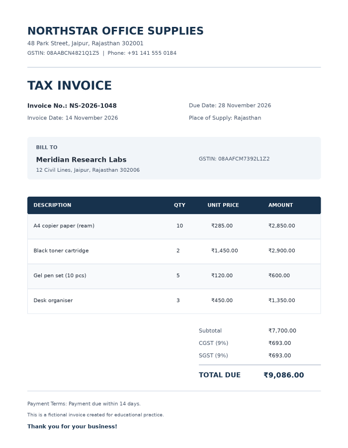

In [4]:
from google.colab import files
from PIL import Image
from IPython.display import display
from pathlib import Path

uploaded = files.upload()
if not uploaded:
    raise ValueError("Upload an invoice or receipt image.")

image_path = next(iter(uploaded.keys()))
image = Image.open(image_path).convert("RGB")
image.thumbnail((448, 448))
print("File:", image_path, "| Size:", image.size)
display(image)


### 5. Define a reusable VQA function

The function takes an image and a natural-language question. It returns the model's answer as text.

In [8]:
from qwen_vl_utils import process_vision_info
from PIL import Image
import torch
import gc

def ask_vlm(image_path, question, max_new_tokens=120):
    # Resize image to reduce GPU memory usage
    image = Image.open(image_path).convert("RGB")
    image.thumbnail((448, 448))

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": question},
        ],
    }]

    prompt = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    generated_ids_trimmed = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(inputs.input_ids, generated_ids)
    ]

    answer = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0].strip()

    del inputs, generated_ids, generated_ids_trimmed
    gc.collect()
    torch.cuda.empty_cache()

    return answer

print("Updated VQA function ready.")


Updated VQA function ready.


In [9]:
question = "What is the invoice number? If it is not clearly readable, say 'not readable'."

answer = ask_vlm(image_path, question)
print(answer)

NS-2026-1048


### 6. Ask targeted invoice questions

Ask about individual fields rather than requesting the entire invoice at once. This makes it easier to inspect errors.

In [10]:
vqa_questions = [
    "What is the invoice number? If it is not clearly readable, say 'not readable'.",
    "What is the invoice date? If it is not clearly readable, say 'not readable'.",
    "What is the supplier or company name?",
    "What is the customer name?",
    "What is the grand total? Do not confuse it with subtotal or tax. If unclear, say 'not readable'.",
]

vqa_answers = []
for q in vqa_questions:
    a = ask_vlm(image_path, q)
    vqa_answers.append({"question": q, "answer": a})
    print("\nQUESTION:", q)
    print("ANSWER:", a)
    torch.cuda.empty_cache()



QUESTION: What is the invoice number? If it is not clearly readable, say 'not readable'.
ANSWER: NS-2026-1048

QUESTION: What is the invoice date? If it is not clearly readable, say 'not readable'.
ANSWER: 14 November 2026

QUESTION: What is the supplier or company name?
ANSWER: The supplier or company name is **NORTHSTAR OFFICE SUPPLIES**.

QUESTION: What is the customer name?
ANSWER: The customer name is **Meridian Research Labs**.

QUESTION: What is the grand total? Do not confuse it with subtotal or tax. If unclear, say 'not readable'.
ANSWER: $9,086.00


### 7. Ask about a line item

Use a question about a visible row. If the invoice has several rows, ask about one specific item or request a short list. The model may omit rows or misread quantities and amounts.

In [11]:
line_item_question = (
    "List the visible invoice line items with their description, quantity, "
    "and amount. If a value is unclear, mark it as unclear rather than guessing."
)
line_item_answer = ask_vlm(image_path, line_item_question, max_new_tokens=350)

print(line_item_answer)


Here are the visible invoice line items with their description, quantity, and amount:

- **Description**: A4 copier paper (ream)  
  **Quantity**: 10  
  **Amount**: ₹2,850.00  

- **Description**: Black toner cartridge  
  **Quantity**: 2  
  **Amount**: ₹2,300.00  

- **Description**: Gel pen set (120 pcs)  
  **Quantity**: 5  
  **Amount**: ₹9,600.00  

- **Description**: Desk organizer  
  **Quantity**: 3  
  **Amount**: ₹1,350.00  

Note: The "Unit Price" column is not explicitly listed for each item in the table, but the "Amount" column is clearly visible and matches the quantity and description. The "Unit Price" is not required to be listed for the answer as per the request.


### 8. Run traditional OCR on the same image

Tesseract extracts recognized text. Unlike a VLM, it does not inherently understand which number is the grand total or which value belongs to a particular field.

In [12]:
import pytesseract

ocr_text = pytesseract.image_to_string(image, config="--psm 6")
print(ocr_text if ocr_text.strip() else "[Tesseract returned no text]")


NORTHSTAR OFFICE SUPPLIES
‘TAX INVOICE



### 9. Compare VQA answers with OCR text

This is a qualitative comparison. Check whether the information requested by the VLM is present in the OCR output. OCR may contain the correct characters but not their semantic relationships; the VLM may infer relationships but can hallucinate or misread digits.

In [13]:
for item in vqa_answers:
    print("=" * 80)
    print("QUESTION:", item["question"])
    print("VLM:", item["answer"])
    print("OCR text contains relevant content? Inspect the OCR output above.")


QUESTION: What is the invoice number? If it is not clearly readable, say 'not readable'.
VLM: NS-2026-1048
OCR text contains relevant content? Inspect the OCR output above.
QUESTION: What is the invoice date? If it is not clearly readable, say 'not readable'.
VLM: 14 November 2026
OCR text contains relevant content? Inspect the OCR output above.
QUESTION: What is the supplier or company name?
VLM: The supplier or company name is **NORTHSTAR OFFICE SUPPLIES**.
OCR text contains relevant content? Inspect the OCR output above.
QUESTION: What is the customer name?
VLM: The customer name is **Meridian Research Labs**.
OCR text contains relevant content? Inspect the OCR output above.
QUESTION: What is the grand total? Do not confuse it with subtotal or tax. If unclear, say 'not readable'.
VLM: $9,086.00
OCR text contains relevant content? Inspect the OCR output above.


### 10. Optional: compare with a managed-service result

If you completed Azure Document Intelligence or AWS Textract in Module 4, upload its raw/normalized JSON output here. If you did not use a managed service, skip this cell. Do not create placeholder values and label them as service output.

In [ ]:
managed_upload = files.upload()

managed_json = None
if managed_upload:
    import json
    managed_path = next(iter(managed_upload.keys()))
    with open(managed_path, "r", encoding="utf-8") as f:
        managed_json = json.load(f)
    print("Loaded managed-service JSON:", managed_path)
    print(json.dumps(managed_json, indent=2, ensure_ascii=False)[:8000])
else:
    print("No managed-service JSON uploaded. Managed-service comparison will be marked unavailable.")


### 11. Build a comparison record

Fill in the reference values only if you have checked them against the invoice. The notebook will preserve your VLM answers, OCR text, and optional managed-service JSON together for review.

This is not an automatic accuracy score unless you provide verified reference values and define a consistent field mapping.

In [16]:
import json
from datetime import datetime
MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"
managed_json = None

comparison_record = {
    "image_filename": Path(image_path).name,
    "vlm_model": MODEL_ID,
    "vlm_answers": vqa_answers,
    "line_item_question": line_item_question,
    "line_item_answer": line_item_answer,
    "tesseract_ocr_text": ocr_text,
    "managed_service_result": managed_json,
    "managed_service_status": "provided" if managed_json is not None else "not available / not run",
    "reference_values": {},
    "created_at": datetime.now().isoformat(timespec="seconds"),
}

output_path = Path("day2_invoice_vqa_comparison.json")
output_path.write_text(
    json.dumps(comparison_record, indent=2, ensure_ascii=False, default=str),
    encoding="utf-8"
)
print("Saved:", output_path.resolve())


Saved: /content/day2_invoice_vqa_comparison.json


12. Observations and Results

The VLM successfully extracted all five key invoice fields: invoice number (NS-2026-1048), invoice date (14 November 2026), supplier name (NORTHSTAR OFFICE SUPPLIES), customer name (Meridian Research Labs), and grand total (9,086.00).

The extracted numerical amount was correct, but the VLM displayed the currency symbol as $ instead of ₹. This shows that although the model can identify financial values and understand their context, it can still make small interpretation errors.

Tesseract OCR provides raw extracted text, whereas the VLM can interpret the meaning of the text and distinguish between fields such as invoice number, customer name, subtotal, and grand total. The OCR output should still be checked against the original invoice to identify any missed or incorrectly recognized text.

No Azure Document Intelligence or AWS Textract comparison was performed because a managed service was not used in this experiment.

Overall, the VLM performed well on this invoice, identifying all five requested fields. However, for financial workflows, I would not rely on VLM output alone. I would validate invoice numbers, dates, currency symbols, tax amounts, and totals against the original document and use deterministic checks for numerical calculations.


**Key takeaway:** OCR primarily recognizes text; VQA uses both image content and a question to generate a contextual answer. Neither is automatically correct. Verify extracted values against the document.

**Next:** Day 3 will use CV model outputs plus an image to generate natural-language explanations and enforce schema-valid JSON.
